# 06 — Évaluation finale unique sur le test-set
Rapport : `reports/06_test_report.md`. Pré-enregistrement : section `final` de `config.yaml`, verrouillée par SHA-256.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
from src.config import load_config
cfg = load_config()
R = ROOT / "reports"; FIG = R / "figures"
def load(name): return json.loads((R / name).read_text())
def fig(name): display(Image(filename=str(FIG / name)))

In [2]:
lock = load('06_test_lock.json'); print({k: lock[k] for k in ('final_sha256', 'first_run')})
from src.evaluation.run_test import _section_hash
print('section final inchangée :', _section_hash(cfg['final']) == lock['final_sha256'])

{'final_sha256': 'a0cf9ce2e774bb425439e1ab1eb05cd24472374c5de137d591578bcf83a9e8c4', 'first_run': '2026-11-22T12:07:03'}


section final inchangée : True


In [3]:
t6 = load('06_test_results.json'); t = pd.DataFrame(t6['test_table']).T
display(t[['MAE','MAE_ci_low','MAE_ci_high','MASE','dMAE_vs_sarima','ci_lo_sarima','ci_hi_sarima','coverage_80','interval_score','daily_volume_bias_kwh']].round(4))

,MAE,MAE_ci_low,MAE_ci_high,MASE,dMAE_vs_sarima,ci_lo_sarima,ci_hi_sarima,coverage_80,interval_score,daily_volume_bias_kwh
naive_24,0.4897,0.4250,0.5472,0.7389,0.0679,0.0281,0.1016,0.8398,2.4101,0.0553
sarima,0.4218,0.3867,0.4571,0.6364,0.0000,0.0000,0.0000,0.8112,2.0404,-0.2502
ridge,0.4155,0.3858,0.4481,0.6269,-0.0063,-0.0183,0.0064,0.7492,1.9791,0.1850
gbm (retenu),0.3813,0.3366,0.4215,0.5753,-0.0405,-0.0581,-0.0237,0.7679,1.9704,1.9328


,naive_24,sarima,ridge,gbm (retenu),n_hours
2010-06,0.509,0.402,0.387,0.363,720
2010-07,0.429,0.395,0.399,0.349,744
2010-08,0.255,0.329,0.342,0.249,623
2010-09,0.477,0.390,0.374,0.365,632
2010-10,0.652,0.526,0.503,0.493,744
2010-11,0.599,0.479,0.481,0.460,600


,MAE_history_imputed,MAE_history_complete,n_hours_imputed
naive_24,0.5186,0.4871,342.0
sarima,0.4586,0.4184,342.0
ridge,0.4317,0.4140,342.0
gbm (retenu),0.4447,0.3755,342.0


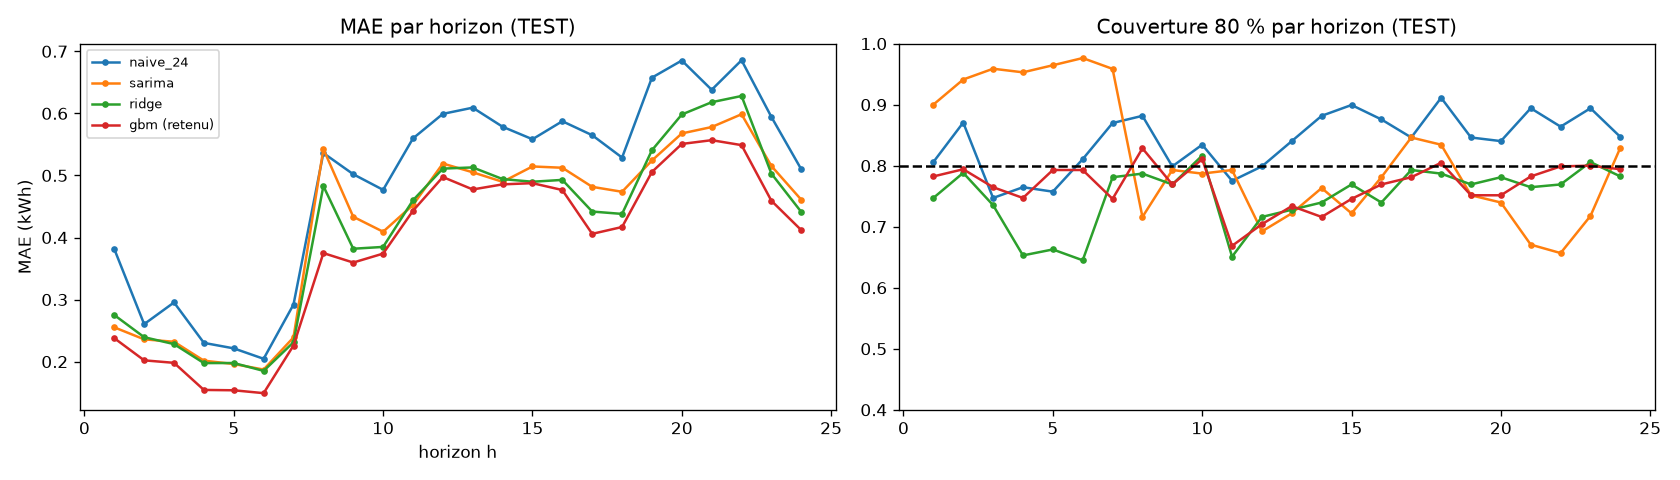

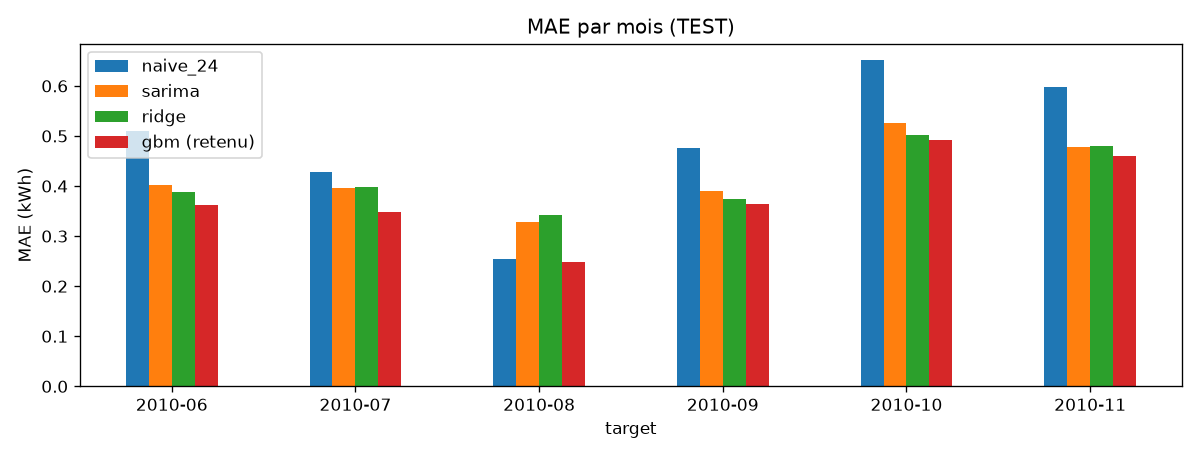

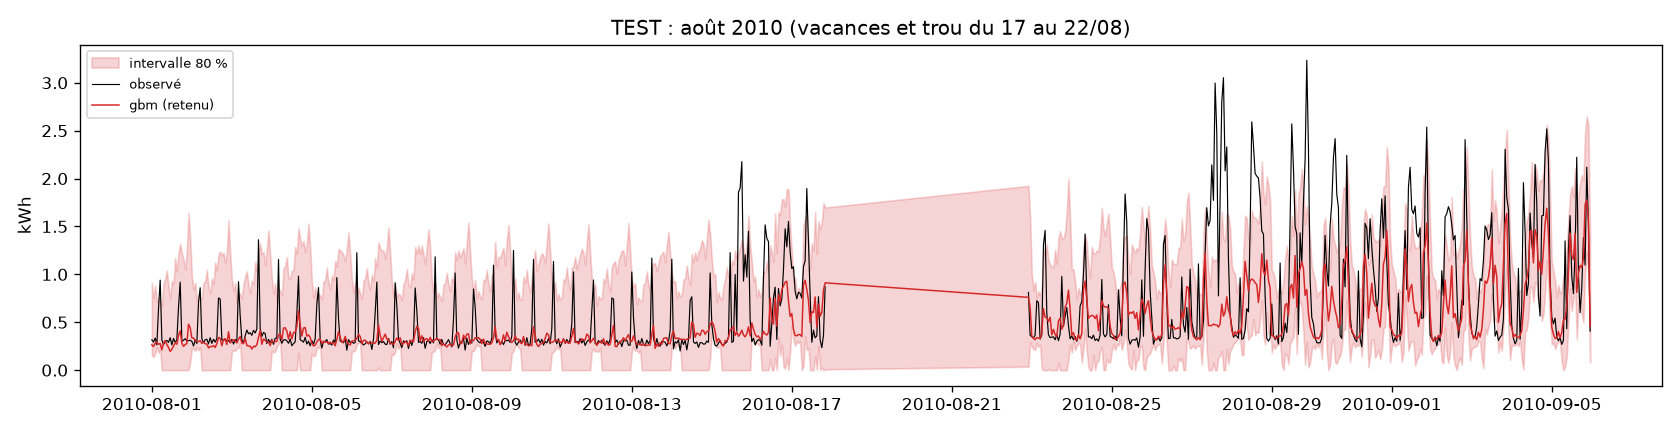

In [4]:
display(pd.DataFrame(t6['mae_by_month']).round(3)); display(pd.DataFrame(t6['gap_effect']).T.round(4))
fig('06_test_by_horizon.png'); fig('06_test_by_month.png'); fig('06_test_august.png')